# 03 · CRAG part 3: the AMBIGUOUS path (books + web together)


## where I am

- CORRECT: refine the good book chunks, generate (01)
- INCORRECT: rewrite query, search the web, refine the web results, generate (02)
- AMBIGUOUS: still a dead end

The SVM vs XGBoost question lands in AMBIGUOUS. One SVM chunk from ISLP scored 0.4, so there's real stuff in the books,
just not enough. And nothing about XGBoost.

## what the paper says (section 4.3)

They describe AMBIGUOUS as a "soft and intermediate action" for when the evaluator isn't confident either way. Since
it can't tell if the retrieval is good or bad, it uses both: the refined internal knowledge (from the books) and the
external knowledge (from the web), combined into one context for the generator.

With the paper's thresholds (appendix B.3, lower -0.99 on a -1 to 1 scale) INCORRECT almost never fires, so I think a
lot of their questions actually end up here. It's probably the most important path, not an edge case.

## the idea before writing any code

I already have almost everything. AMBIGUOUS needs:
- web results, which the INCORRECT path already gets (rewrite_query -> web_search)
- the good book docs, which are already in the state as `good_docs` from the evaluate step

So I don't need a new branch at all. AMBIGUOUS can just go down the same path as INCORRECT, and the refine node
decides what to refine based on the verdict:

```
verdict      what refine uses
CORRECT      good_docs
INCORRECT    web_docs
AMBIGUOUS    good_docs + web_docs
```

That means the router only needs two outputs now: CORRECT goes straight to refine, everything else goes to
rewrite_query first. Three branches turn into two. This works because of the shared state, the good docs are still
sitting there from the evaluate step when the web docs arrive.

## setup

In [1]:
import os
import re
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)  # langchain-community sunset notice
from pathlib import Path
from typing import Literal, TypedDict
from urllib.parse import urlparse

from dotenv import load_dotenv
from langchain_community.vectorstores import FAISS
from langchain_core.documents import Document
from langchain_core.prompts import ChatPromptTemplate
from langchain_openai import ChatOpenAI, OpenAIEmbeddings
from langgraph.graph import StateGraph, START, END
from pydantic import BaseModel, Field
from tavily import TavilyClient

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
load_dotenv(PROJECT_ROOT / ".env")

INDEX_DIR = PROJECT_ROOT / "vectorstore" / "faiss_index"
assert INDEX_DIR.exists(), "Run 00_simple_rag.ipynb first to build the FAISS index."

embeddings = OpenAIEmbeddings(model=os.environ["OPENAI_EMBEDDING_MODEL"])
vectorstore = FAISS.load_local(str(INDEX_DIR), embeddings, allow_dangerous_deserialization=True)
retriever = vectorstore.as_retriever(search_type="similarity", search_kwargs={"k": 4})
llm = ChatOpenAI(model=os.environ["OPENAI_CHAT_MODEL"], temperature=0)
tavily = TavilyClient(api_key=os.environ["TAVILY_API_KEY"])

TEST_QUERIES = {
    "in_corpus": "Explain the bias-variance trade-off.",
    "recent": "What were the top AI news stories in the last month?",
    "out_of_corpus": "What is the transformer architecture in deep learning?",
    "partial": "Compare support vector machines with XGBoost for tabular data.",
}

### pieces from 01 and 02

Evaluator, verdict logic, refinement, query rewrite and Tavily search, all unchanged. (The Wikipedia switch is in 02,
I left it out here to keep this shorter.)

In [2]:
LOWER_THRESHOLD = 0.3
UPPER_THRESHOLD = 0.7
Verdict = Literal["CORRECT", "INCORRECT", "AMBIGUOUS"]


def decide_verdict(scores: list[float], lower: float = LOWER_THRESHOLD, upper: float = UPPER_THRESHOLD) -> tuple[Verdict, str]:
    if any(s > upper for s in scores):
        return "CORRECT", f"At least one chunk scored above {upper}."
    if all(s < lower for s in scores):
        return "INCORRECT", f"All chunks scored below {lower}."
    return "AMBIGUOUS", f"No chunk scored above {upper}, but not all were below {lower}."


def describe(doc: Document) -> str:
    if "url" in doc.metadata:
        return f"web: {urlparse(doc.metadata['url']).netloc.removeprefix('www.')}"
    return f"{Path(doc.metadata.get('source', '?')).name[:22]} p.{doc.metadata.get('page', '?')}"


# ---- evaluator (v2 rubric from 01)
class ChunkEvaluation(BaseModel):
    score: float = Field(description="Relevance score between 0.0 and 1.0")
    reason: str = Field(description="One short sentence explaining the score")


evaluator_prompt = ChatPromptTemplate.from_messages([
    ("system",
     "You are a strict retrieval evaluator for a RAG system. You are given a question and ONE retrieved chunk.\n"
     "Score how useful the chunk is for answering the question, between 0.0 and 1.0:\n"
     "- 0.8-1.0: directly and substantially answers the question (or its main part)\n"
     "- 0.4-0.7: answers PART of the question (e.g. covers one of the things being compared) or gives a key piece of the answer\n"
     "- 0.1-0.2: same broad topic, but contains nothing that helps answer this question\n"
     "- 0.0: unrelated\n"
     "Be conservative with high scores. Give a one-sentence reason."),
    ("human", "Question: {question}\n\nChunk:\n{chunk}"),
])
evaluator_chain = evaluator_prompt | llm.with_structured_output(ChunkEvaluation)


def evaluate_docs(question: str, docs: list[Document]) -> list[ChunkEvaluation]:
    inputs = [{"question": question, "chunk": d.page_content} for d in docs]
    results = evaluator_chain.batch(inputs, config={"max_concurrency": 8})
    for r in results:
        r.score = min(max(r.score, 0.0), 1.0)
    return results


# ---- knowledge refinement (from 01)
MIN_STRIP_CHARS = 25


def decompose_to_strips(text: str) -> list[str]:
    text = " ".join(text.split())
    sentences = re.split(r"(?<=[.!?])\s+(?=[A-Z0-9(\"'])", text)
    return [s.strip() for s in sentences if len(s.strip()) >= MIN_STRIP_CHARS]


class StripDecision(BaseModel):
    keep: bool = Field(description="True only if the sentence directly helps answer the question")


strip_filter_prompt = ChatPromptTemplate.from_messages([
    ("system",
     "You are a strict relevance filter. Return keep=true ONLY if the sentence directly helps answer the question. "
     "Judge the sentence on its own."),
    ("human", "Question: {question}\n\nSentence: {strip}"),
])
strip_filter_chain = strip_filter_prompt | llm.with_structured_output(StripDecision)


def refine_docs(question: str, docs: list[Document]) -> dict:
    strips, sources = [], []
    for doc in docs:
        for s in decompose_to_strips(doc.page_content):
            strips.append(s)
            sources.append(describe(doc))

    inputs = [{"question": question, "strip": s} for s in strips]
    keep_flags = [d.keep for d in strip_filter_chain.batch(inputs, config={"max_concurrency": 8})] if strips else []
    kept = [(src, s) for src, s, k in zip(sources, strips, keep_flags) if k]

    return {
        "strips": strips,
        "kept_strips": [s for _, s in kept],
        "kept_sources": [src for src, _ in kept],
        "refined_context": "\n".join(s for _, s in kept),
    }


# ---- query rewrite + web search (from 02)
class WebQuery(BaseModel):
    query: str = Field(description="Short keyword-style web search query")
    needs_recent: bool = Field(description="True if the question is about recent or time-sensitive events")


rewrite_prompt = ChatPromptTemplate.from_messages([
    ("system",
     "Rewrite the user's question into a web search query.\n"
     "- use keywords, not a full sentence (about 4-12 words)\n"
     "- keep the important entities and technical terms\n"
     "- set needs_recent=true only if the question is about recent/latest/current events\n"
     "- do NOT answer the question"),
    ("human", "Question: {question}"),
])
rewrite_chain = rewrite_prompt | llm.with_structured_output(WebQuery)


def web_search(query: str, recent: bool = False, max_results: int = 5) -> list[Document]:
    kwargs = {"topic": "news", "time_range": "month"} if recent else {}
    response = tavily.search(query, max_results=max_results, **kwargs)
    return [
        Document(page_content=f"{r['title']}\n{r['content']}", metadata={"title": r["title"], "url": r["url"]})
        for r in response.get("results", [])
    ]

---
## step 1: doing the ambiguous case by hand first

Before touching the graph I want to run the steps manually on the SVM vs XGBoost question and look at each piece.

First: what does the evaluator keep from the books?

In [3]:
pq = TEST_QUERIES["partial"]
book_docs = retriever.invoke(pq)
evals = evaluate_docs(pq, book_docs)
scores = [e.score for e in evals]
verdict, reason = decide_verdict(scores)
good_docs = [d for d, s in zip(book_docs, scores) if s > LOWER_THRESHOLD]

print(f"verdict: {verdict} ({reason})\n")
for d, e in zip(book_docs, evals):
    print(f"  {'keep' if e.score > LOWER_THRESHOLD else 'drop'} {e.score:.2f}  {describe(d):<30} {e.reason}")
print(f"\ngood_docs: {len(good_docs)}")

verdict: AMBIGUOUS (No chunk scored above 0.7, but not all were below 0.3.)

  keep 0.40  ISLP_website.pdf p.394         The chunk provides information about support vector machines but does not compare them with XGBoost.
  drop 0.10  ISLP_website.pdf p.368         The chunk discusses boosting and test MSE but does not provide a comparison between support vector machines and XGBoost.
  drop 0.10  ISLP_website.pdf p.399         The chunk discusses support vector machines but does not provide any comparison with XGBoost or relevant information about tabular data.
  drop 0.10  ISLP_website.pdf p.400         The chunk discusses support vector machines but does not provide any comparison with XGBoost.

good_docs: 1


Then the web part, same as the INCORRECT path:

In [4]:
wq = rewrite_chain.invoke({"question": pq})
web_docs = web_search(wq.query, recent=wq.needs_recent)

print(f"rewritten: {wq.query!r} (recent={wq.needs_recent})\n")
for d in web_docs:
    print(f"  {describe(d):<30} {d.metadata['title'][:70]}")

rewritten: 'support vector machines vs XGBoost tabular data' (recent=False)

  web: mdpi.com                  Comparative Analysis and Optimisation of Machine Learning Models for R
  web: inflammatix.com           Searching for the Best Tabular Data Classifiers - Inflammatix
  web: geeksforgeeks.org         Support Vector Machine vs Extreme Gradient Boosting - GeeksforGeeks
  web: medium.com                Basic Comparison Between RandomForest, SVM, and XGBoost
  web: eigenvector.com           A Comparison of ANNs, SVMs & XGBoost on some ...


Now refine both together and check where the kept sentences came from. If this works, the SVM parts should be at
least partly from the book and the XGBoost parts have to come from the web.

In [5]:
combined = refine_docs(pq, good_docs + web_docs)

from_book = [s for src, s in zip(combined["kept_sources"], combined["kept_strips"]) if not src.startswith("web:")]
from_web = [s for src, s in zip(combined["kept_sources"], combined["kept_strips"]) if src.startswith("web:")]
print(f"kept {len(combined['kept_strips'])}/{len(combined['strips'])} strips: {len(from_book)} from the books, {len(from_web)} from the web\n")

for src, s in zip(combined["kept_sources"], combined["kept_strips"]):
    print(f"  [{src}] {s[:200]}")

kept 8/32 strips: 0 from the books, 8 from the web

  [web: mdpi.com] Comparative Analysis and Optimisation of Machine Learning Models for Regression and Classification on Structured Tabular Datasets linear/logistic regression, support vector machines (SVMs), Extreme Gr
  [web: mdpi.com] Each family employs task-appropriate implementations: linear/logistic regression (Ordinary Least Squares (OLS) for regression, logistic loss for classification), SVM (Support Vector Regression (SVR) w
  [web: inflammatix.com] We also included Logistic Regression and Support Vector Machine algorithms as benchmarks. [...] Further we noticed that in these studies neural networks outperformed tree-based algorithms on 12 out of
  [web: geeksforgeeks.org] Support Vector Machine vs Extreme Gradient Boosting - GeeksforGeeks ## Conclusion SVM and XGBoost are different types of algorithms with distinct strengths and weaknesses.
  [web: geeksforgeeks.org] SVM is powerful for finding optimal decision boundaries, e

Hmm. In my run it's 0 from the books and 6 from the web.

The one SVM chunk that passed the evaluator (ISLP p.394) is from the lab section, it's mostly code like
`plot_svm(X, y, svm_linear, ax=ax)`. It scored 0.4 because the chunk as a whole is about SVMs. But once it's split into
sentences, none of them actually helps compare SVMs to anything, so the strip filter dropped every one of them.

So the evaluator and the filter judge different things. The evaluator looks at the whole chunk ("is this about the
topic?"), the filter looks at single sentences ("does this sentence help answer?"). A chunk can pass the first and
lose everything in the second. Here that turned AMBIGUOUS into basically INCORRECT. Not wrong really, the book
genuinely had nothing useful for this comparison. The extra question at the end is a better example of real mixing.

---
## step 2: the graph

Only two things change compared to 02:
1. `refine_node` picks `good_docs + web_docs` when the verdict is AMBIGUOUS
2. the router has two outputs instead of three, and the ambiguous stub node is gone

The state is exactly the same as 02.

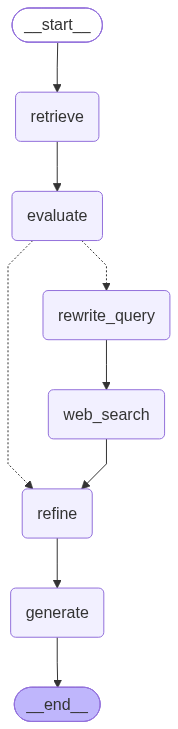

In [6]:
class State(TypedDict):
    question: str
    docs: list[Document]
    scores: list[float]
    score_reasons: list[str]
    good_docs: list[Document]
    verdict: Verdict
    reason: str
    web_query: str
    needs_recent: bool
    web_docs: list[Document]
    strips: list[str]
    kept_strips: list[str]
    kept_sources: list[str]
    refined_context: str
    answer: str


def retrieve_node(state: State) -> dict:
    return {"docs": retriever.invoke(state["question"])}


def evaluate_node(state: State) -> dict:
    evals = evaluate_docs(state["question"], state["docs"])
    scores = [e.score for e in evals]
    verdict, reason = decide_verdict(scores)
    return {
        "scores": scores,
        "score_reasons": [e.reason for e in evals],
        "good_docs": [d for d, s in zip(state["docs"], scores) if s > LOWER_THRESHOLD],
        "verdict": verdict,
        "reason": reason,
    }


def rewrite_query_node(state: State) -> dict:
    wq = rewrite_chain.invoke({"question": state["question"]})
    return {"web_query": wq.query, "needs_recent": wq.needs_recent}


def web_search_node(state: State) -> dict:
    return {"web_docs": web_search(state["web_query"], recent=state["needs_recent"])}


def refine_node(state: State) -> dict:
    if state["verdict"] == "CORRECT":
        source_docs = state["good_docs"]
    elif state["verdict"] == "INCORRECT":
        source_docs = state["web_docs"]
    else:  # AMBIGUOUS: internal + external
        source_docs = state["good_docs"] + state["web_docs"]
    return refine_docs(state["question"], source_docs)


answer_prompt = ChatPromptTemplate.from_messages([
    ("system",
     "You are a helpful ML tutor. Answer ONLY using the provided context. "
     "If the context is empty or insufficient, say: 'I don't know.'"),
    ("human", "Question: {question}\n\nContext:\n{context}"),
])


def generate_node(state: State) -> dict:
    out = (answer_prompt | llm).invoke({"question": state["question"], "context": state["refined_context"]})
    return {"answer": out.content}


def route_after_eval(state: State) -> str:
    return "refine" if state["verdict"] == "CORRECT" else "rewrite_query"


g = StateGraph(State)
g.add_node("retrieve", retrieve_node)
g.add_node("evaluate", evaluate_node)
g.add_node("rewrite_query", rewrite_query_node)
g.add_node("web_search", web_search_node)
g.add_node("refine", refine_node)
g.add_node("generate", generate_node)

g.add_edge(START, "retrieve")
g.add_edge("retrieve", "evaluate")
g.add_conditional_edges("evaluate", route_after_eval, {"refine": "refine", "rewrite_query": "rewrite_query"})
g.add_edge("rewrite_query", "web_search")
g.add_edge("web_search", "refine")
g.add_edge("refine", "generate")
g.add_edge("generate", END)
app = g.compile()

from IPython.display import Image, display

try:
    display(Image(app.get_graph().draw_mermaid_png()))
except Exception:  # rendering needs internet (mermaid.ink); fall back to text
    print(app.get_graph().draw_mermaid())

The graph looks simpler than 02 even though it handles more cases. The verdict now only decides two things: whether
we search the web, and what refine uses.

---
## step 3: all four questions

This is the first time every question gets a real answer.

In [7]:
def run(key: str) -> dict:
    r = app.invoke({"question": TEST_QUERIES[key]})
    print(f"Q: {r['question']}\n")
    print(f"Verdict: {r['verdict']} ({r['reason']})")
    for i, (d, s) in enumerate(zip(r["docs"], r["scores"]), 1):
        print(f"  {'✓' if s > LOWER_THRESHOLD else '✗'} d{i} {s:.2f}  {describe(d)}")

    if r["verdict"] != "CORRECT":
        print(f"\nRewritten query: {r['web_query']!r} (recent={r['needs_recent']}), {len(r['web_docs'])} web results")
    n_book = sum(not s.startswith("web:") for s in r["kept_sources"])
    print(f"Refinement: kept {len(r['kept_strips'])}/{len(r['strips'])} strips "
          f"({n_book} from books, {len(r['kept_sources']) - n_book} from web)")

    print(f"\nAnswer:\n{r['answer']}")
    if r["kept_sources"]:
        print("\nSources used:")
        for src in dict.fromkeys(r["kept_sources"]):
            print(f"  - {src}")
    return r

### SVM vs XGBoost (AMBIGUOUS, the new path)

In [8]:
r_partial = run("partial")

Q: Compare support vector machines with XGBoost for tabular data.

Verdict: AMBIGUOUS (No chunk scored above 0.7, but not all were below 0.3.)
  ✓ d1 0.40  ISLP_website.pdf p.394
  ✗ d2 0.10  ISLP_website.pdf p.368
  ✗ d3 0.10  ISLP_website.pdf p.399
  ✗ d4 0.10  ISLP_website.pdf p.400

Rewritten query: 'support vector machines vs XGBoost tabular data' (recent=False), 5 web results
Refinement: kept 8/32 strips (0 from books, 8 from web)

Answer:
Support Vector Machines (SVM) and Extreme Gradient Boosting (XGBoost) are both powerful algorithms used for classification and regression tasks, but they have distinct strengths and weaknesses.

SVM is particularly effective at finding optimal decision boundaries, especially in high-dimensional spaces. It uses techniques like Support Vector Regression (SVR) and linear Support Vector Classification (SVC) to handle different types of data. SVM tends to perform well when the data is linearly separable.

On the other hand, XGBoost excels at capturi

Compare this with 00. There the strict prompt answer described XGBoost from the model's memory with zero XGBoost
chunks in the context. Now the XGBoost part comes from web sources that are listed right there.

The book didn't contribute anything this time (see step 1), a bit disappointing but honest.

### the other three, making sure nothing broke

In [9]:
r_in = run("in_corpus")

Q: Explain the bias-variance trade-off.

Verdict: CORRECT (At least one chunk scored above 0.7.)
  ✗ d1 0.10  ISLP_website.pdf p.47
  ✓ d2 0.80  ISLP_website.pdf p.43
  ✓ d3 0.80  ISLP_website.pdf p.43
  ✓ d4 0.40  Bishop-Pattern-Recogni p.166
Refinement: kept 6/17 strips (6 from books, 0 from web)

Answer:
The bias-variance trade-off refers to the balance between two types of errors that affect the performance of a statistical learning method: bias and variance. Bias is the error due to overly simplistic assumptions in the learning algorithm, leading to systematic errors in predictions (high bias). Variance, on the other hand, is the error due to excessive sensitivity to fluctuations in the training data, resulting in models that may fit the training data very closely but perform poorly on unseen data (high variance).

The challenge is to find a model that minimizes both bias and variance, leading to low test mean squared error (MSE). Typically, as model flexibility increases, test MS

In [10]:
r_recent = run("recent")

Q: What were the top AI news stories in the last month?

Verdict: INCORRECT (All chunks scored below 0.3.)
  ✗ d1 0.10  ISLP_website.pdf p.405
  ✗ d2 0.00  ISLP_website.pdf p.405
  ✗ d3 0.10  ISLP_website.pdf p.431
  ✗ d4 0.10  ISLP_website.pdf p.405

Rewritten query: 'top AI news stories last month' (recent=True), 5 web results
Refinement: kept 10/26 strips (0 from books, 10 from web)

Answer:
The top AI news stories in the last month include:

1. Leading AI firms signed an accord on development during a White House summit, committing to voluntary safety standards and internal controls.
2. OpenAI canceled the rollout of its GPT-6.1 Astra system due to security concerns, as it "didn't quite meet the bar" for company standards.
3. Trump announced plans to name a new AI czar, likely Jay Clayton, amid growing debates on managing AI risks.
4. A federal appeals court ruled that the US government could blacklist Anthropic from Department of Defense contracts.
5. Both Anthropic and OpenAI CEO

In [11]:
r_ooc = run("out_of_corpus")

Q: What is the transformer architecture in deep learning?

Verdict: INCORRECT (All chunks scored below 0.3.)
  ✗ d1 0.00  ISLP_website.pdf p.416
  ✗ d2 0.00  ISLP_website.pdf p.457
  ✗ d3 0.00  ISLP_website.pdf p.418
  ✗ d4 0.00  ISLP_website.pdf p.454

Rewritten query: 'transformer architecture deep learning' (recent=False), 5 web results
Refinement: kept 9/28 strips (0 from books, 9 from web)

Answer:
The transformer architecture is an instance of the encoder–decoder architecture used in deep learning, which can operate with either the encoder or the decoder individually. It employs multi-head self-attention to represent input and output sequences, with the decoder maintaining an autoregressive property through a masked version. The architecture includes input and output sequence embeddings combined with positional encoding before being processed by stacked modules based on self-attention. Initially proposed for sequence-to-sequence learning, transformers have since been applied acro

---
## one more check: a different half-covered question

The 4 test questions are kind of hand picked at this point, so I want to try one I didn't tune anything for.
Gradient boosting is in ISLP, LightGBM isn't.

In [12]:
TEST_QUERIES["extra_partial"] = "How does gradient boosting work, and what does LightGBM do differently?"
r_extra = run("extra_partial")

Q: How does gradient boosting work, and what does LightGBM do differently?

Verdict: AMBIGUOUS (No chunk scored above 0.7, but not all were below 0.3.)
  ✓ d1 0.60  ISLP_website.pdf p.354
  ✓ d2 0.40  ISLP_website.pdf p.367
  ✗ d3 0.10  mml-book.pdf p.237
  ✓ d4 0.40  ISLP_website.pdf p.355

Rewritten query: 'gradient boosting LightGBM differences' (recent=False), 5 web results
Refinement: kept 15/69 strips (6 from books, 9 from web)

Answer:
Gradient boosting works by building decision trees sequentially, where each tree is trained to correct the errors made by the previous trees. Instead of fitting a single large decision tree, it fits trees to the residuals of the current model, allowing for a gradual learning process. 

LightGBM differentiates itself from other gradient boosting algorithms like XGBoost by using Gradient-based One-Side Sampling (GOSS) to filter data instances for finding split values, rather than relying on pre-sorted or histogram-based methods. Additionally, LightG

This one actually shows the mixing. Look at the refinement line: some strips from ISLP, more from the web.

The first part of the answer (trees grown one after another on the residuals, learning slowly) is basically ISLP's
explanation. The LightGBM part (leaf-wise growth, GOSS, feature bundling) comes from the web, one of the sources is
even the LightGBM paper on neurips.cc. That's what AMBIGUOUS is supposed to look like.

One thing that worries me a bit: the best gradient boosting chunk scored 0.6. If it had scored 0.8 this would have gone
CORRECT, only the book would be used, and the LightGBM half would have no source at all. CORRECT means "at least one
chunk is great", not "the whole question is covered". Multi-part questions are the weak spot.
